# Title

**Exercise 2 - Simple k-NN Classification and Logistic Regression**

# Description
The aim of this exercise is to fit, interpret, predict, score, and plot simple $k$-NN classification and logistic regression models using the `sklearn` package.

# Dataset Description
The dataset used here is the Heart dataset. It has several predictors such as `Age`, `Sex`, and `MaxHR`. First we use only `Age` to predict whether or not someone has atherosclerotic heart disease (AHD). In the last question we add `MaxHR` and `Sex`.

# Instructions
1. Read the `Heart.csv` file into a pandas data frame.
2. Split the dataset into train and validation sets, with 75% of the data for training.
3. Assign the predictor and response variables. The aim is to predict whether a patient has `AHD`.
4. Fit a $k$-NN model (manually tuned) to the dataset and look at some predictions.
5. Fit a logistic regression model to the dataset and interpret the coefficients.
6. Do some work mathematically based on the estimated model.
7. Compute and print the train and validation accuracies for both models.
8. Plot the predictions on the scatterplot.

In [1]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

### Read in the dataset

In [2]:
# Read the "Heart.csv" dataset and take a quick look
heart = pd.read_csv('Heart.csv')

# Force the response into a binary indicator
heart['AHD'] = 1 * (heart['AHD'] == "Yes")

print(heart.shape)
heart.head()

(303, 15)


,Unnamed: 0,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,1,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,0
1,2,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,1
2,3,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,1
3,4,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,0
4,5,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,0


In [3]:
# split into train and validation
heart_train, heart_val = train_test_split(heart, train_size=0.75, random_state=109)

print(heart_train.shape, heart_val.shape)

(227, 15) (76, 15)


### $k$-NN model fitting

Define and fit a $k$-NN classification model with $k=20$ to predict `AHD` from `Age`.

In [4]:
# select variables for model estimation: be careful of format
# (single square brackets give a Series, double square brackets give a DataFrame)
x_train = heart_train[['Age']]
y_train = heart_train['AHD']

# define the model
knn20 = KNeighborsClassifier(n_neighbors=20)

# fit to the data
knn20.fit(x_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",20
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


### $k$-NN prediction

There are two types of predictions in classification models in sklearn: `predict` for pure classifications and `predict_proba` for probabilities.

In [5]:
# create the predictions based on the train data
yhat20_class = knn20.predict(x_train)
yhat20_prob = knn20.predict_proba(x_train)

# print out the first 10 predictions
print(yhat20_class[:10])
print(yhat20_prob[:10])

[0 0 1 1 1 0 1 1 0 1]
[[0.7  0.3 ]
 [0.8  0.2 ]
 [0.4  0.6 ]
 [0.25 0.75]
 [0.3  0.7 ]
 [0.7  0.3 ]
 [0.45 0.55]
 [0.3  0.7 ]
 [0.7  0.3 ]
 [0.35 0.65]]


**What do you notice about the probability estimates? Which 'column' is which? How could you manually create `yhat20_class` from `yhat20_prob`?**

The first column is the probability of class 0 (no AHD) and the second column is the probability of class 1 (AHD). The two columns add up to 1 in every row. With $k=20$ the probabilities can only be multiples of 1/20 (0, 0.05, 0.10, ...), because they are the fraction of the 20 nearest neighbours that have AHD. To create `yhat20_class` manually, pick the class with the higher probability, i.e. predict 1 when the second column is above 0.5.

In [6]:
# check the manual rule gives the same result as predict()
manual_class = (yhat20_prob[:, 1] > 0.5).astype(int)
print("Same as predict():", np.mean(manual_class == yhat20_class))

Same as predict(): 1.0


### Simple logistic regression model fitting

In [7]:
# Logistic regression with no penalty
logit1 = LogisticRegression(penalty=None, max_iter=1000)

# Fit the model using the training set
logit1.fit(x_train, y_train)

# Get the coefficient estimates
print("Logistic Regression Estimated Betas (B0, B1):", logit1.intercept_, logit1.coef_)

Logistic Regression Estimated Betas (B0, B1): [-3.32616703] [[0.05933142]]


c:\Users\biaon\Desktop\DataScience\Section5\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


### Interpret the Coefficient Estimates

In [8]:
b0 = logit1.intercept_[0]
b1 = logit1.coef_[0][0]
print(f"b0 = {b0:.5f}, b1 = {b1:.5f}")

b0 = -3.32617, b1 = 0.05933


The estimated model is

$$ \ln\left(\frac{P(Y=1)}{1-P(Y=1)}\right) = \hat{\beta}_0 + \hat{\beta}_1 X = -3.32617 + 0.05933 \cdot \text{Age}$$

Each additional year of age increases the log-odds of AHD by 0.0593, which means the odds are multiplied by $e^{0.0593} \approx 1.061$ (about 6.1% higher odds per year).

**What are the estimated odds that a 60-year-old has AHD? What is the probability?**

In [9]:
# odds and probability for a 60-year-old
log_odds_60 = b0 + b1 * 60
odds_60 = np.exp(log_odds_60)
prob_60 = odds_60 / (1 + odds_60)

print("log-odds:", log_odds_60)
print("odds:", odds_60)
print("probability:", prob_60)

# check with sklearn (double brackets / DataFrame keeps the column name)
print("predict_proba:", logit1.predict_proba(pd.DataFrame({'Age': [60]}))[0, 1])

log-odds: 0.23371819534321991
odds: 1.2632884414760925
probability: 0.5581650214464885
predict_proba: 0.5581650214464884


For a 60-year-old: log-odds $\approx 0.234$, odds $\approx 1.26$, and probability $\approx 0.56$ (56%).

### Accuracy computation: $k$-NN and logistic

In [10]:
# Define the equivalent validation variables from `heart_val`
x_val = heart_val[['Age']]
y_val = heart_val['AHD']

# Compute the training and validation accuracy using the estimator.score() function
knn20_train_accuracy = knn20.score(x_train, y_train)
knn20_val_accuracy = knn20.score(x_val, y_val)

logit_train_accuracy = logit1.score(x_train, y_train)
logit_val_accuracy = logit1.score(x_val, y_val)

print("k-NN Train & Validation Accuracy:", knn20_train_accuracy, knn20_val_accuracy)
print("Logistic Train & Validation Accuracy:", logit_train_accuracy, logit_val_accuracy)

k-NN Train & Validation Accuracy: 0.6299559471365639 0.5526315789473685
Logistic Train & Validation Accuracy: 0.6387665198237885 0.6052631578947368


### Plot the predictions

We use a 'dummy' x variable for plotting. Train and validation data are plotted separately (validation points are shifted slightly to tell them apart), together with 4 types of predictions: pure classification and probability estimation for each model.

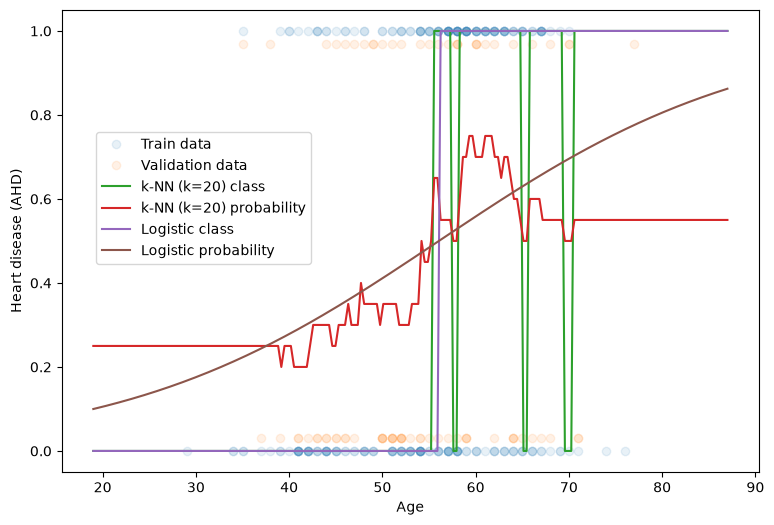

In [11]:
# dummy x for plotting: extended a little beyond the observed range of Age
x_fit = pd.DataFrame({'Age': np.linspace(heart['Age'].min() - 10, heart['Age'].max() + 10, 200)})

yhat_class_knn20 = knn20.predict(x_fit)
yhat_prob_knn20 = knn20.predict_proba(x_fit)[:, 1]

yhat_class_logit = logit1.predict(x_fit)
yhat_prob_logit = logit1.predict_proba(x_fit)[:, 1]

plt.figure(figsize=(9, 6))

# observed data (validation points offset to differentiate them from train)
plt.plot(x_train, y_train, 'o', alpha=0.1, label='Train data')
plt.plot(x_val, 0.94 * y_val + 0.03, 'o', alpha=0.1, label='Validation data')

# predictions
plt.plot(x_fit, yhat_class_knn20, label='k-NN (k=20) class')
plt.plot(x_fit, yhat_prob_knn20, label='k-NN (k=20) probability')
plt.plot(x_fit, yhat_class_logit, label='Logistic class')
plt.plot(x_fit, yhat_prob_logit, label='Logistic probability')

plt.legend(loc=(0.05, 0.45))
plt.xlabel("Age")
plt.ylabel("Heart disease (AHD)")
plt.show()

### Post exercise questions

**1. Describe the estimated associations between AHD and Age based on these two models.**

Both models show a positive association: older patients are more likely to have AHD. In the logistic regression the association is smooth and monotonic: each extra year of age adds 0.059 to the log-odds (odds ratio about 1.06), so the probability rises gradually and crosses 0.5 at about $-\hat\beta_0/\hat\beta_1 \approx 56$ years. The $k$-NN model shows the same general trend, but its estimated probability is a bumpy step function that goes up and down locally, because it only averages the 20 closest ages.

**2. Which model appears to be more overfit to the training data? How do you know? How can this be resolved?**

The $k$-NN model is more overfit. Its predicted class and probability jump between 0 and 1 across neighbouring ages, following noise in the training data, whereas the logistic curve is smooth. Overfitting also shows up in the gap between training and validation accuracy, which is larger for $k$-NN (compare the accuracies printed above). It can be resolved by increasing $k$ (a smoother, less flexible model) and choosing $k$ with a validation set or cross-validation.

**3. How could you engineer features for the logistic regression model so that the association between AHD and Age resembles the general trend in the knn20 model more closely?**

Add polynomial features of Age (Age$^2$, Age$^3$, ...), so the logistic model can bend and have local ups and downs like $k$-NN. The degree should be chosen with validation data to avoid overfitting.

In [12]:
from sklearn.preprocessing import PolynomialFeatures

for degree in [1, 2, 3, 4]:
    poly_logit = make_pipeline(
        PolynomialFeatures(degree, include_bias=False),
        StandardScaler(),
        LogisticRegression(max_iter=5000),
    ).fit(x_train, y_train)
    print(degree, poly_logit.score(x_train, y_train), poly_logit.score(x_val, y_val))

1 0.6387665198237885 0.6052631578947368
2 0.6431718061674009 0.6052631578947368
3 0.6519823788546255 0.6052631578947368
4 0.6475770925110133 0.5789473684210527


**4. Refit the models above to predict `AHD` from 3 predictors (and play around with $k$):** `['MaxHR', 'Age', 'Sex']`. Investigate the associations in each of the two models and evaluate the predictive accuracy of each of these models.

In [13]:
predictors = ['MaxHR', 'Age', 'Sex']

x_train3 = heart_train[predictors]
x_val3 = heart_val[predictors]
# y_train and y_val stay the same

#### Logistic regression with 3 predictors

In [14]:
logit3 = LogisticRegression(penalty=None, max_iter=1000).fit(x_train3, y_train)

print("Intercept:", logit3.intercept_[0])
for name, coef in zip(predictors, logit3.coef_[0]):
    print(f"{name:6s} coefficient = {coef: .4f}   odds ratio = {np.exp(coef):.3f}")

print("Train accuracy:     ", logit3.score(x_train3, y_train))
print("Validation accuracy:", logit3.score(x_val3, y_val))

Intercept: 2.615822140892954
MaxHR  coefficient = -0.0383   odds ratio = 0.962
Age    coefficient =  0.0395   odds ratio = 1.040
Sex    coefficient =  1.2277   odds ratio = 3.414
Train accuracy:      0.7092511013215859
Validation accuracy: 0.7105263157894737


c:\Users\biaon\Desktop\DataScience\Section5\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


#### $k$-NN with 3 predictors (trying different $k$)

$k$-NN uses distances, so predictors on larger scales dominate (`MaxHR` ranges over about 100 units while `Sex` is 0/1). We standardize the predictors first with `StandardScaler`, fitted on the training data only (the pipeline does this automatically).

    k  train_acc  val_acc
0   1      0.996    0.658
1   3      0.833    0.671
2   5      0.780    0.724
3  10      0.744    0.763
4  20      0.740    0.789
5  30      0.718    0.789
6  50      0.696    0.737


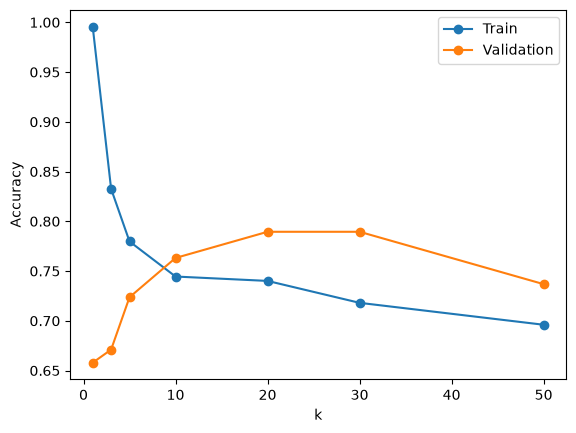

In [15]:
ks = [1, 3, 5, 10, 20, 30, 50]
results = []

for k in ks:
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(x_train3, y_train)
    results.append((k, knn.score(x_train3, y_train), knn.score(x_val3, y_val)))

results = pd.DataFrame(results, columns=['k', 'train_acc', 'val_acc'])
print(results.round(3))

plt.plot(results['k'], results['train_acc'], 'o-', label='Train')
plt.plot(results['k'], results['val_acc'], 'o-', label='Validation')
plt.xlabel('k'); plt.ylabel('Accuracy'); plt.legend(); plt.show()

In [16]:
# best k according to the validation set
best_k = int(results.loc[results['val_acc'].idxmax(), 'k'])
print("Best k:", best_k)

knn3 = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k)).fit(x_train3, y_train)

# baseline: always predict the majority class
baseline = max(y_val.mean(), 1 - y_val.mean())

print("k-NN train accuracy:        ", knn3.score(x_train3, y_train))
print("k-NN validation accuracy:   ", knn3.score(x_val3, y_val))
print("Logistic validation accuracy:", logit3.score(x_val3, y_val))
print("Baseline (majority class):   ", baseline)

Best k: 20
k-NN train accuracy:         0.7400881057268722
k-NN validation accuracy:    0.7894736842105263
Logistic validation accuracy: 0.7105263157894737
Baseline (majority class):    0.6052631578947368


#### Plot: probability of AHD as a function of Age

With 3 predictors we can only plot one variable at a time. We vary `Age` and hold `MaxHR` at its mean and `Sex` fixed (here `Sex = 1`).

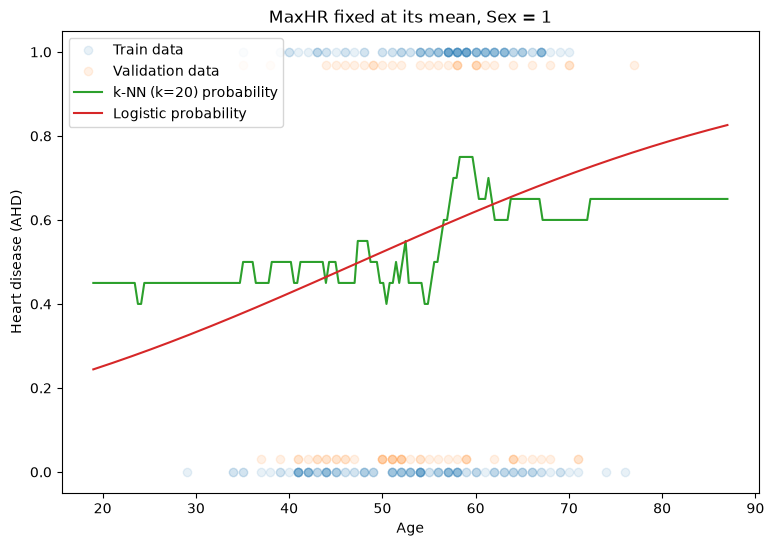

In [17]:
age_grid = np.linspace(heart['Age'].min() - 10, heart['Age'].max() + 10, 200)

x_plot = pd.DataFrame({
    'MaxHR': heart['MaxHR'].mean(),
    'Age': age_grid,
    'Sex': 1,
})[predictors]

plt.figure(figsize=(9, 6))
plt.plot(heart_train['Age'], y_train, 'o', alpha=0.1, label='Train data')
plt.plot(heart_val['Age'], 0.94 * y_val + 0.03, 'o', alpha=0.1, label='Validation data')
plt.plot(age_grid, knn3.predict_proba(x_plot)[:, 1], label=f'k-NN (k={best_k}) probability')
plt.plot(age_grid, logit3.predict_proba(x_plot)[:, 1], label='Logistic probability')
plt.xlabel('Age'); plt.ylabel('Heart disease (AHD)')
plt.title('MaxHR fixed at its mean, Sex = 1')
plt.legend(); plt.show()

#### Interpretation

**Associations (logistic regression, 3 predictors).** Holding the other predictors fixed:
- `MaxHR` has a negative coefficient (-0.038, odds ratio 0.96): each extra beat per minute of maximum heart rate lowers the odds of AHD by about 4%.
- `Age` has a positive coefficient (+0.040, odds ratio 1.04): each extra year raises the odds of AHD by about 4%.
- `Sex` has the largest effect (+1.23, odds ratio 3.41): men (`Sex = 1`) have about 3.4 times the odds of AHD compared to women with the same age and `MaxHR`.

**Associations ($k$-NN).** $k$-NN has no coefficients, so the associations are read from its predictions (for example the plot above): the predicted probability of AHD increases with Age and with Sex = 1, and decreases with MaxHR, in agreement with the logistic model, but with a less smooth shape.

**Effect of $k$.** With $k=1$ the model memorizes the training data (train accuracy about 0.996, validation about 0.658): it is clearly overfit. As $k$ grows the training accuracy falls and the validation accuracy rises, peaking at $k = 20$ to $30$ (validation about 0.789). For very large $k$ ($k=50$) the model becomes too smooth and validation accuracy drops again (0.737).

**Predictive accuracy** (random_state = 109):

| Model | Train | Validation |
|---|---|---|
| Logistic regression (Age only) | 0.639 | 0.605 |
| Logistic regression (MaxHR, Age, Sex) | 0.709 | 0.711 |
| k-NN, k=20, Age only | 0.656 | 0.592 |
| k-NN, k=20, 3 predictors (standardized) | 0.740 | 0.789 |

Baseline (always predict the majority class): 0.605 on the validation set. Adding `MaxHR` and `Sex` clearly improves both models over the Age-only versions, which are barely better than the baseline. The standardized $k$-NN with $k=20$ is the most accurate on the validation set, while the logistic regression has nearly identical train and validation accuracy (no overfitting) and is easier to interpret. Note that the validation set has only 76 patients, so differences of a few percentage points are within random variation.